# PPI QSAR — Bond-aware Graph Neural Network (GINE)

**Goal:** Predict molecule-level median pIC₅₀ from a molecular graph and compare against the previously established Morgan-fingerprint Random Forest baseline.

**Data:** `PPI_descriptors.csv` (248 unique molecules), produced in your preceding notebook. Place the file next to this notebook.

**Evaluation:** Recreate the earlier `random_state=42` random and Murcko scaffold test splits; reserve an independent validation subset **within each training portion**; select the best epoch by validation MAE; evaluate the test portion only at the end.

This is a small-data exploratory model, not evidence of validated molecular potency. Molecule-level activity labels combine assays and can be inconsistent.


## Setup

In a **new conda environment** (recommended in view of prior PyTorch crashes):

```bash
conda create -n ppi_gnn python=3.11 -y
conda activate ppi_gnn
python -m pip install --upgrade pip
python -m pip install torch --index-url https://download.pytorch.org/whl/cu130
python -m pip install torch_geometric rdkit pandas numpy scikit-learn matplotlib ipykernel
python -m ipykernel install --user --name ppi_gnn --display-name "Python (ppi_gnn)"
```

Select **Python (ppi_gnn)** as the VS Code notebook kernel. The listed CUDA build is for compatible Linux/WSL drivers; for other systems or if this build does not work, use the command provided at https://pytorch.org/get-started/locally/ (CPU-only installation is also adequate for 248 compounds). Do not install PyTorch into the old crashing environment.


In [2]:
import random, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from torch import nn
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GINEConv, global_mean_pool

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Device: {device}")

Device: cuda


## Load data and reproduce the previous test splits

In [3]:
df = pd.read_csv('PPI_descriptors.csv').reset_index(drop=True)
required = ['canonical_smiles', 'pIC50_median', 'molecule_chembl_id']
assert all(col in df.columns for col in required)
assert df['molecule_chembl_id'].is_unique, 'Expected one row per molecule'
assert df['pIC50_median'].notna().all()
mols = [Chem.MolFromSmiles(s) for s in df['canonical_smiles']]
assert all(m is not None for m in mols)
y = df['pIC50_median'].to_numpy(dtype=np.float32)
scaffolds = np.asarray([MurckoScaffold.MurckoScaffoldSmiles(mol=m) for m in mols])
idx = np.arange(len(df))
random_trainpool, random_test = train_test_split(idx, test_size=0.20, random_state=42)
outer = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
scaffold_trainpool, scaffold_test = next(outer.split(idx, y, groups=scaffolds))

# Validation is selected *only within* the training pool.
random_train, random_val = train_test_split(random_trainpool, test_size=0.20, random_state=17)
inner = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=17)
inner_tr, inner_val = next(inner.split(scaffold_trainpool, groups=scaffolds[scaffold_trainpool]))
scaffold_train, scaffold_val = scaffold_trainpool[inner_tr], scaffold_trainpool[inner_val]

splits = {
  'Random': (random_train, random_val, random_test),
  'Scaffold': (scaffold_train, scaffold_val, scaffold_test),
}
for name,(tr,va,te) in splits.items():
    assert not (set(tr)&set(va) or set(tr)&set(te) or set(va)&set(te))
    if name == 'Scaffold':
        assert not (set(scaffolds[tr])&set(scaffolds[te]))
        assert not (set(scaffolds[va])&set(scaffolds[te]))
        assert not (set(scaffolds[tr])&set(scaffolds[va]))
    print(name, 'train/val/test:', len(tr), len(va), len(te))
print('Unique Murcko scaffolds:', len(set(scaffolds)))


Random train/val/test: 158 40 50
Scaffold train/val/test: 168 42 38
Unique Murcko scaffolds: 61


## Graph representation

Atom descriptors include element one-hot, degree, formal charge, aromaticity, hydrogen count, and hybridization. Bonds are represented by one-hot bond type plus conjugation and ring flags. This model is **bond-aware** (`GINEConv`) and operates only on the 2-D chemical graph, not 3-D conformations.


In [4]:
ELEMENTS = ['C','N','O','S','F','Cl','Br','I','P','B','Si']
BOND_TYPES = [Chem.BondType.SINGLE, Chem.BondType.DOUBLE,
              Chem.BondType.TRIPLE, Chem.BondType.AROMATIC]
HYBRID = [Chem.HybridizationType.SP, Chem.HybridizationType.SP2,
          Chem.HybridizationType.SP3]

def one_hot_unknown(value, categories):
    return [float(value == v) for v in categories] + [float(value not in categories)]

def atom_features(atom):
    return (one_hot_unknown(atom.GetSymbol(), ELEMENTS)
            + one_hot_unknown(atom.GetDegree(), list(range(6)))
            + one_hot_unknown(atom.GetFormalCharge(), [-2,-1,0,1,2])
            + one_hot_unknown(atom.GetTotalNumHs(), list(range(5)))
            + one_hot_unknown(atom.GetHybridization(), HYBRID)
            + [float(atom.GetIsAromatic()), float(atom.IsInRing())])

def bond_features(bond):
    return (one_hot_unknown(bond.GetBondType(), BOND_TYPES)
            + [float(bond.GetIsConjugated()), float(bond.IsInRing())])

NODE_DIM = len(atom_features(mols[0].GetAtomWithIdx(0)))
EDGE_DIM = len(bond_features(mols[0].GetBondWithIdx(0)))

def mol_to_graph(mol, target):
    x = torch.tensor([atom_features(a) for a in mol.GetAtoms()], dtype=torch.float32)
    edges, attrs = [], []
    for bond in mol.GetBonds():
        a,b = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        feat = bond_features(bond)
        edges.extend([[a,b], [b,a]])
        attrs.extend([feat, feat])
    if edges:
        edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
        edge_attr = torch.tensor(attrs, dtype=torch.float32)
    else:
        edge_index = torch.empty((2,0), dtype=torch.long)
        edge_attr = torch.empty((0,EDGE_DIM), dtype=torch.float32)
    return Data(x=x, edge_index=edge_index, edge_attr=edge_attr,
                y=torch.tensor([float(target)], dtype=torch.float32))

graphs = [mol_to_graph(mol, yi) for mol,yi in zip(mols,y)]
print('Graph count:',len(graphs),'Atom feature count:',NODE_DIM,'Bond feature count:',EDGE_DIM)


Graph count: 248 Atom feature count: 37 Bond feature count: 7


## GINE architecture and training

In [5]:
class GINERegressor(nn.Module):
    def __init__(self, node_dim=NODE_DIM, edge_dim=EDGE_DIM, hidden=64, dropout=0.25):
        super().__init__()
        self.atom_encoder = nn.Linear(node_dim, hidden)
        self.convs = nn.ModuleList()
        self.norms = nn.ModuleList()
        for _ in range(3):
            mlp = nn.Sequential(nn.Linear(hidden,hidden), nn.ReLU(),
                                nn.Linear(hidden,hidden))
            self.convs.append(GINEConv(mlp, edge_dim=edge_dim))
            self.norms.append(nn.LayerNorm(hidden))
        self.dropout = dropout
        self.head = nn.Sequential(nn.Linear(hidden,32),nn.ReLU(),
                                  nn.Dropout(dropout),nn.Linear(32,1))

    def forward(self, batch):
        x = F.relu(self.atom_encoder(batch.x))
        for conv,norm in zip(self.convs,self.norms):
            x = F.relu(norm(conv(x,batch.edge_index,batch.edge_attr)))
            x = F.dropout(x,p=self.dropout,training=self.training)
        x = global_mean_pool(x,batch.batch)
        return self.head(x).view(-1)

@torch.no_grad()
def predict(model, loader):
    model.eval()
    pred=[]; true=[]
    for batch in loader:
        batch=batch.to(device)
        pred.extend(model(batch).cpu().numpy())
        true.extend(batch.y.view(-1).cpu().numpy())
    return np.asarray(true),np.asarray(pred)

def run_experiment(name, tr, va, te, max_epochs=400, patience=45):
    # Standardize targets using training labels only.
    mu=float(np.mean(y[tr])); sigma=float(np.std(y[tr]))
    assert sigma > 0
    normalized = [mol_to_graph(mol, (yi-mu)/sigma) for mol,yi in zip(mols,y)]
    train_loader=DataLoader([normalized[i] for i in tr],batch_size=32,shuffle=True)
    val_loader=DataLoader([normalized[i] for i in va],batch_size=64,shuffle=False)
    test_loader=DataLoader([normalized[i] for i in te],batch_size=64,shuffle=False)
    model=GINERegressor().to(device)
    optimizer=torch.optim.AdamW(model.parameters(),lr=1e-3,weight_decay=1e-4)
    best=float('inf'); best_epoch=0; best_state=None; history=[]
    for epoch in range(1,max_epochs+1):
        model.train(); losses=[]
        for batch in train_loader:
            batch=batch.to(device)
            optimizer.zero_grad()
            p=model(batch)
            loss=F.mse_loss(p,batch.y.view(-1))
            loss.backward()
            optimizer.step()
            losses.append(float(loss.item()))
        vtrue,vpred=predict(model,val_loader)
        val_mae=float(np.mean(np.abs(vtrue-vpred)))
        history.append({'epoch':epoch,'train_mse_normalized':np.mean(losses),
                        'val_mae_normalized':val_mae})
        if val_mae < best-1e-4:
            best=val_mae; best_epoch=epoch
            best_state=copy.deepcopy(model.state_dict())
        if epoch-best_epoch >= patience:
            break
    model.load_state_dict(best_state)
    ynorm,pnorm=predict(model,test_loader)
    ytrue=ynorm*sigma+mu; ypred=pnorm*sigma+mu
    metrics={'Split':name,'Model':'GINE','MAE':mean_absolute_error(ytrue,ypred),
             'RMSE':np.sqrt(mean_squared_error(ytrue,ypred)),
             'R2':r2_score(ytrue,ypred),'Best epoch':best_epoch,
             'Train size':len(tr),'Validation size':len(va),'Test size':len(te)}
    print(name, {k:round(float(v),3) if isinstance(v,(float,np.floating)) else v
                 for k,v in metrics.items()})
    return model,pd.DataFrame(history),metrics,ytrue,ypred


## Train on random and scaffold splits

For comparing against your previously published RF numbers: both models use the **same held-out test indices**, but the GNN uses only part of the original RF training pool for weight updates because validation data are held back. This is a useful initial comparison but not a matched validation/tuning protocol. In a paper, rerun the RF baseline with the same validation discipline and multiple seeds.


In [6]:
outcomes = {}
for name,(tr,va,te) in splits.items():
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    outcomes[name] = run_experiment(name,tr,va,te)

metrics_df = pd.DataFrame([outcomes[name][2] for name in splits])
display(metrics_df.round(3))
metrics_df.to_csv('PPI_GINE_results.csv',index=False)


Random {'Split': 'Random', 'Model': 'GINE', 'MAE': 0.496, 'RMSE': 0.661, 'R2': 0.34, 'Best epoch': 144, 'Train size': 158, 'Validation size': 40, 'Test size': 50}
Scaffold {'Split': 'Scaffold', 'Model': 'GINE', 'MAE': 0.569, 'RMSE': 0.799, 'R2': 0.314, 'Best epoch': 82, 'Train size': 168, 'Validation size': 42, 'Test size': 38}


,Split,Model,MAE,RMSE,R2,Best epoch,Train size,Validation size,Test size
0,Random,GINE,0.496,0.661,0.340,144,158,40,50
1,Scaffold,GINE,0.569,0.799,0.314,82,168,42,38


## Learning curves and predicted-versus-experimental scatter

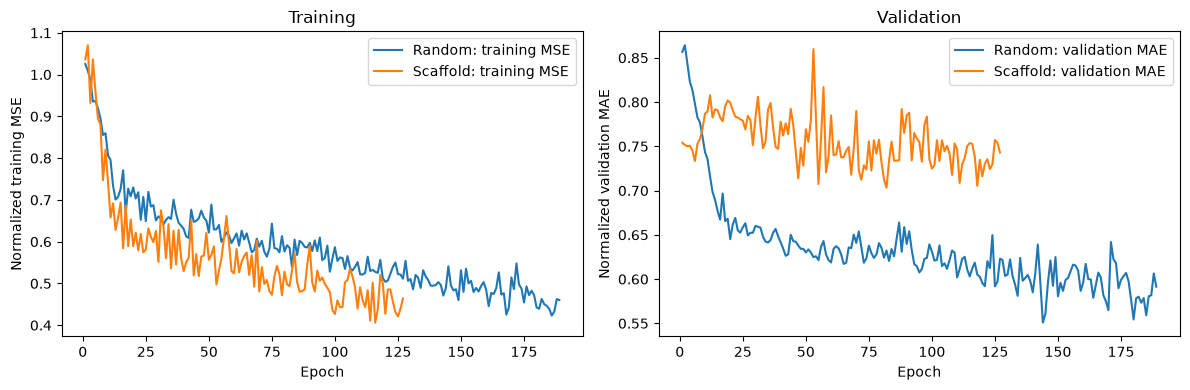

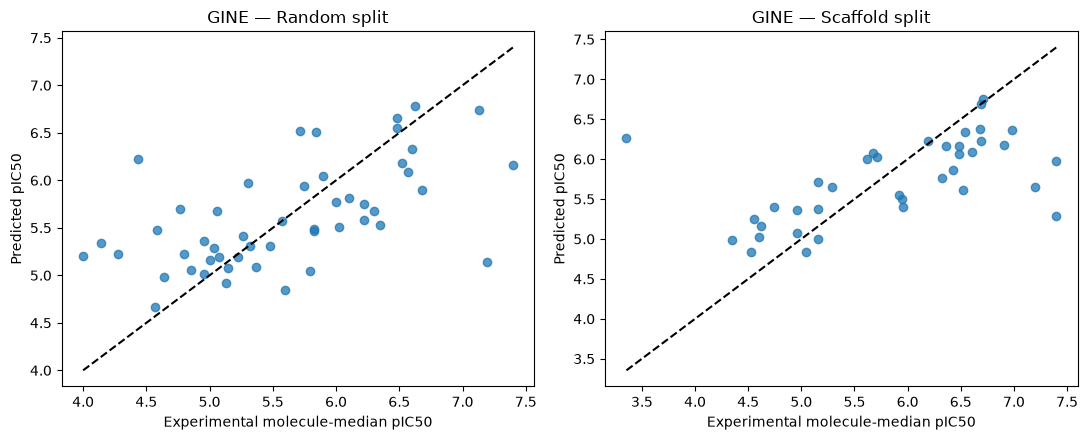

In [7]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for name in splits:
    hist=outcomes[name][1]
    axes[0].plot(hist['epoch'],hist['train_mse_normalized'],label=f'{name}: training MSE')
    axes[1].plot(hist['epoch'],hist['val_mae_normalized'],label=f'{name}: validation MAE')
axes[0].set(xlabel='Epoch',ylabel='Normalized training MSE',title='Training')
axes[1].set(xlabel='Epoch',ylabel='Normalized validation MAE',title='Validation')
for ax in axes: ax.legend()
plt.tight_layout();plt.show()

fig,axes=plt.subplots(1,2,figsize=(11,4.5))
for ax,name in zip(axes,splits):
    actual,pred=outcomes[name][3],outcomes[name][4]
    lo=min(actual.min(),pred.min()); hi=max(actual.max(),pred.max())
    ax.scatter(actual,pred,alpha=.75)
    ax.plot([lo,hi],[lo,hi],'k--')
    ax.set(xlabel='Experimental molecule-median pIC50',
           ylabel='Predicted pIC50',title=f'GINE — {name} split')
plt.tight_layout();plt.show()


## Compare against the recorded Random Forest numbers

These RF measurements are from your previous run and are *not recomputed in this notebook*. They use the same test indices but no separate validation holdout; see the caveat above.


In [8]:
rf_reference = pd.DataFrame([
  {'Split':'Random','Model':'RF Morgan FP','MAE':0.389,'RMSE':0.505,'R2':0.615},
  {'Split':'Scaffold','Model':'RF Morgan FP','MAE':0.544,'RMSE':0.765,'R2':0.372},
])
comparison = pd.concat([rf_reference,metrics_df[['Split','Model','MAE','RMSE','R2']]],ignore_index=True)
display(comparison.round(3))
comparison.to_csv('PPI_RF_vs_GINE.csv',index=False)


,Split,Model,MAE,RMSE,R2
0,Random,RF Morgan FP,0.389,0.505,0.615
1,Scaffold,RF Morgan FP,0.544,0.765,0.372
2,Random,GINE,0.496,0.661,0.340
3,Scaffold,GINE,0.569,0.799,0.314


In [15]:
class GINETunable(nn.Module):
    def __init__(
        self,
        node_dim=NODE_DIM,
        edge_dim=EDGE_DIM,
        hidden=32,
        num_layers=2,
        dropout=0.2
    ):
        super().__init__()

        self.atom_encoder = nn.Linear(node_dim, hidden)

        self.convs = nn.ModuleList()
        self.norms = nn.ModuleList()

        for _ in range(num_layers):
            mlp = nn.Sequential(
                nn.Linear(hidden, hidden),
                nn.ReLU(),
                nn.Linear(hidden, hidden)
            )
            self.convs.append(GINEConv(mlp, edge_dim=edge_dim))
            self.norms.append(nn.LayerNorm(hidden))

        self.dropout = dropout

        self.head = nn.Sequential(
            nn.Linear(hidden, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1)
        )

    def forward(self, batch):
        x = F.relu(self.atom_encoder(batch.x))

        for conv, norm in zip(self.convs, self.norms):
            h = conv(x, batch.edge_index, batch.edge_attr)
            x = F.relu(norm(h))
            x = F.dropout(
                x, p=self.dropout, training=self.training
            )

        x = global_mean_pool(x, batch.batch)

        return self.head(x).view(-1)

@torch.no_grad()
def predict(model, loader):
    model.eval()
    pred=[]; true=[]
    for batch in loader:
        batch=batch.to(device)
        pred.extend(model(batch).cpu().numpy())
        true.extend(batch.y.view(-1).cpu().numpy())
    return np.asarray(true),np.asarray(pred)

def run_experiment(name, tr, va, te, max_epochs=400, patience=45, model_class=GINETunable, model_kwargs=None, learning_rate=1e-3):
    # Standardize targets using training labels only.
    mu=float(np.mean(y[tr])); sigma=float(np.std(y[tr]))
    assert sigma > 0
    normalized = [mol_to_graph(mol, (yi-mu)/sigma) for mol,yi in zip(mols,y)]
    train_loader=DataLoader([normalized[i] for i in tr],batch_size=32,shuffle=True)
    val_loader=DataLoader([normalized[i] for i in va],batch_size=64,shuffle=False)
    test_loader=DataLoader([normalized[i] for i in te],batch_size=64,shuffle=False)
    if model_kwargs is None:
        model_kwargs = {}
    model = model_class(**model_kwargs).to(device)
    #model=GINETunable.to(device)
    optimizer=torch.optim.AdamW(model.parameters(),lr=learning_rate,weight_decay=1e-4)
    best=float('inf'); best_epoch=0; best_state=None; history=[]
    for epoch in range(1,max_epochs+1):
        model.train(); losses=[]
        for batch in train_loader:
            batch=batch.to(device)
            optimizer.zero_grad()
            p=model(batch)
            loss=F.mse_loss(p,batch.y.view(-1))
            loss.backward()
            optimizer.step()
            losses.append(float(loss.item()))
        vtrue,vpred=predict(model,val_loader)
        val_mae=float(np.mean(np.abs(vtrue-vpred)))
        history.append({'epoch':epoch,'train_mse_normalized':np.mean(losses),
                        'val_mae_normalized':val_mae})
        if val_mae < best-1e-4:
            best=val_mae; best_epoch=epoch
            best_state=copy.deepcopy(model.state_dict())
        if epoch-best_epoch >= patience:
            break
    model.load_state_dict(best_state)
    ynorm,pnorm=predict(model,test_loader)
    ytrue=ynorm*sigma+mu; ypred=pnorm*sigma+mu
    metrics={'Split':name,'Model':'GINE','MAE':mean_absolute_error(ytrue,ypred),
             'RMSE':np.sqrt(mean_squared_error(ytrue,ypred)),
             'R2':r2_score(ytrue,ypred),'Best epoch':best_epoch,
             'Train size':len(tr),'Validation size':len(va),'Test size':len(te)}
    print(name, {k:round(float(v),3) if isinstance(v,(float,np.floating)) else v
                 for k,v in metrics.items()})
    return model,pd.DataFrame(history),metrics,ytrue,ypred    

In [16]:
config = {
    "hidden": 32,
    "num_layers": 2,
    "dropout": 0.2
}

results = {}

for split_name, (tr, va, te) in splits.items():

    print(f"\nTraining: {split_name}")

    model, history, metrics, y_true, y_pred = (
        run_experiment(
            split_name,
            tr, va, te,
            model_class=GINETunable,
            model_kwargs=config,
            learning_rate=0.001
        )
    )

    results[split_name] = metrics

display(pd.DataFrame(results.values()).round(3))


Training: Random
Random {'Split': 'Random', 'Model': 'GINE', 'MAE': 0.481, 'RMSE': 0.604, 'R2': 0.449, 'Best epoch': 271, 'Train size': 158, 'Validation size': 40, 'Test size': 50}

Training: Scaffold
Scaffold {'Split': 'Scaffold', 'Model': 'GINE', 'MAE': 0.779, 'RMSE': 0.912, 'R2': 0.109, 'Best epoch': 11, 'Train size': 168, 'Validation size': 42, 'Test size': 38}


,Split,Model,MAE,RMSE,R2,Best epoch,Train size,Validation size,Test size
0,Random,GINE,0.481,0.604,0.449,271,158,40,50
1,Scaffold,GINE,0.779,0.912,0.109,11,168,42,38


## Interpretation and next work

- Better random-split than scaffold-split performance suggests dependence on familiar chemotypes.
- The assay-median pIC₅₀ values are noisy labels; inspect within-compound assay disagreement.
- With 248 molecules, performance depends on split choice and seed. Next: repeat nested training/validation experiments across 5–10 seeds, quantify uncertainty, and compare a hyperparameter-matched RF.
- Only after this should a GNN be used as a scoring component for generated molecules. In particular, flag generated molecules outside the predictor's applicability domain.
